[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/03_optimization.ipynb)

# 03 · Optimization: How Models Actually Learn

**Part 0 — Foundations** · Notebook 3 of 27

Notebook 02 told us **what** to minimize (a negative log-likelihood, i.e. a loss). This notebook is about **how**. Training any model, from a straight line to GPT, means finding the bottom of a loss landscape, usually one we can't see, in thousands or billions of dimensions. We'll start with a hiker lost in the fog (CX 4240's picture) and end with Adam, the optimizer that trains almost every modern neural network.

**What you'll learn**

1. Every ML problem is an optimization problem
2. Loss landscapes: bowls, valleys and bumpy terrain
3. Random search, and why it fails in high dimensions
4. Optimality conditions: what "the bottom" looks like
5. Local search
6. **Gradient descent**: derivation, learning rates, convergence, feature scaling
7. Convex vs. non-convex problems; local minima and saddle points
8. **Stochastic gradient descent (SGD)** and mini-batches
9. Momentum, RMSProp and **Adam**
10. Constrained optimization: Lagrange multipliers and KKT conditions

*Course map: CX 4240 Lecture 4 (Brief Intro to Optimization); ISYE 4600 W7 (Basic Optimization: convexity, KKT, empirical risk minimization).*

In [1]:
#@title ⚙️ Setup — run this cell first (imports, plot style, helpers)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display, Markdown
import ipywidgets as widgets
from ipywidgets import interact, FloatSlider, IntSlider

# One consistent, colorblind-checked palette used across the whole series
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#4a3aa7", red="#e34948",
         ink="#0b0b0b", muted="#52514e", light="#d9d8d3")
plt.rcParams.update({
    "figure.figsize": (6.4, 4.2), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
        ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
    "lines.linewidth": 2, "font.size": 11, "legend.frameon": False,
    "animation.embed_limit": 40, "animation.frame_format": "jpeg",   # JPEG frames keep notebooks small
})

def show_anim(anim):
    """Render a matplotlib animation as an interactive player (play / pause / scrub)."""
    plt.close(anim._fig)
    return HTML(anim.to_jshtml(default_mode="once"))

rng = np.random.default_rng(0)
print("Setup complete ✓")
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

def contour(ax, f, xlim, ylim, levels=30, log=False, n=300, cmap="Blues_r"):
    """Filled contour plot of f(x, y) over a box; returns the grid for reuse."""
    xs, ys = np.linspace(*xlim, n), np.linspace(*ylim, n)
    X, Y = np.meshgrid(xs, ys)
    Z = f(np.stack([X, Y]))
    ax.contourf(X, Y, np.log10(Z + 1e-12) if log else Z, levels=levels, cmap=cmap)
    ax.contour(X, Y, np.log10(Z + 1e-12) if log else Z, levels=levels, colors="white", linewidths=0.4, alpha=0.5)
    ax.set(xlim=xlim, ylim=ylim); ax.grid(False)
    return X, Y, Z

def plot_path(ax, path, color, label=None, ms=3):
    ax.plot(path[:, 0], path[:, 1], "-o", color=color, ms=ms, lw=1.6, label=label)
    ax.plot(*path[0], "o", color=color, ms=9, markeredgecolor="white")
    ax.plot(*path[-1], "*", color=color, ms=15, markeredgecolor=C["ink"])

# Test functions we'll reuse. Each takes p = [x, y] (arrays of any shape).
himmelblau   = lambda p: (p[0]**2 + p[1] - 11)**2 + (p[0] + p[1]**2 - 7)**2
himmelblau_g = lambda p: np.array([4*p[0]*(p[0]**2 + p[1] - 11) + 2*(p[0] + p[1]**2 - 7),
                                   2*(p[0]**2 + p[1] - 11) + 4*p[1]*(p[0] + p[1]**2 - 7)])
rosen   = lambda p: (1 - p[0])**2 + 100 * (p[1] - p[0]**2)**2
rosen_g = lambda p: np.array([-2*(1 - p[0]) - 400*p[0]*(p[1] - p[0]**2), 200*(p[1] - p[0]**2)])
print("Helpers ready ✓")

Setup complete ✓
Helpers ready ✓


---
## 1. Every ML problem is an optimization problem

ISYE 4600 (W7) writes almost every learning problem in one template, **regularized empirical risk minimization**:

$$\min_{\theta} \;\; \underbrace{\frac{1}{n}\sum_{i=1}^{n} L\big(y_i, f_\theta(x_i)\big)}_{\text{average loss on the data}} \;+\; \underbrace{\lambda R(\theta)}_{\text{regularizer}}$$

An optimization problem has three components:

| Component | Generic name | In ML |
|---|---|---|
| what you can change | **decision variables** | the model parameters $\theta$ |
| what you want small | **objective function** | the loss (+ regularization) |
| what's not allowed | **constraints** | e.g. $\lVert\theta\rVert \le t$, probabilities sum to 1, SVM margins |

And there are three ways to solve one, all of which you'll meet in this series:

| Approach | Examples |
|---|---|
| **Closed form**: solve the optimality equations exactly | linear regression's normal equation, PCA's eigendecomposition |
| **Special-purpose algorithms** | k-means' assign/update steps, EM for mixtures |
| **General iterative methods** | gradient descent, SGD, Adam: what trains neural networks |

---
## 2. Loss landscapes

Picture the loss as terrain: every point is a choice of parameters, and the height is the loss. Two very different kinds of terrain:

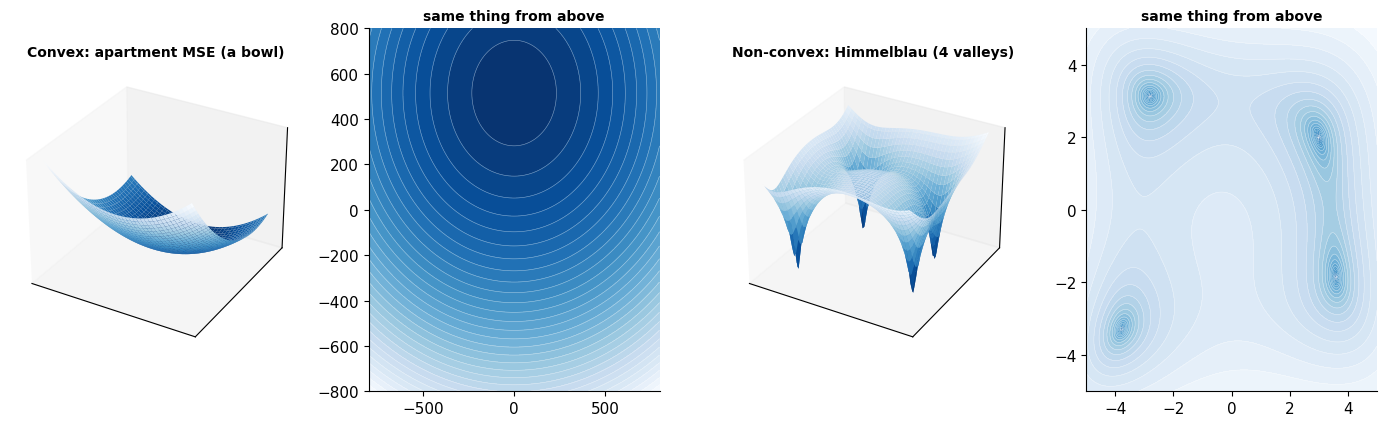

In [2]:
# (a) The apartment-rent MSE from notebook 00 (standardized feature) — a perfect bowl
rng_a = np.random.default_rng(0)
n = 60
area = rng_a.uniform(300, 1400, n)
bedrooms = np.clip(np.round(area / 450 + rng_a.normal(0, 0.4, n)), 1, 4)
rent = 500 + 1.4 * area + 100 * bedrooms + rng_a.normal(0, 150, n)
z = (area - area.mean()) / area.std()
y_c = rent - rent.mean()                                       # center rent so the bowl sits near the origin
mse = lambda p: np.mean((y_c - (p[0][..., None] + p[1][..., None] * z)) ** 2, axis=-1) / 1e5

fig = plt.figure(figsize=(14, 4.4))
for i, (f, lim, name, log) in enumerate([(mse, (-800, 800), "Convex: apartment MSE (a bowl)", False),
                                          (himmelblau, (-5, 5), "Non-convex: Himmelblau (4 valleys)", True)]):
    g = np.linspace(*lim, 80); GX, GY = np.meshgrid(g, g); Z = f(np.stack([GX, GY]))
    ax = fig.add_subplot(1, 4, 2 * i + 1, projection="3d")
    ax.plot_surface(GX, GY, np.log10(Z + 1) if log else Z, cmap="Blues_r", edgecolor="none")
    ax.set_title(name, fontsize=10); ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
    ax2 = fig.add_subplot(1, 4, 2 * i + 2)
    contour(ax2, f, lim, lim, log=log)
    ax2.set_title("same thing from above", fontsize=10)
fig.tight_layout(); plt.show()

The bowl has exactly one lowest point and every downhill path leads to it. The bumpy landscape has several valleys, so *where you start* determines where you end up. Neural network losses are bumpy, in millions of dimensions.

---
## 3. Random search: the lost hiker

CX 4240 Lecture 4 starts with a hiker who wants to reach the lowest point of a valley but can't see the terrain. The simplest strategy: **teleport to random spots, remember the lowest one**.

### 🎬 Random search on Himmelblau's function

In [3]:
pts = rng.uniform(-5, 5, size=(120, 2))
vals = himmelblau(pts.T)
best_idx = np.array([np.argmin(vals[:k + 1]) for k in range(len(pts))])

fig, ax = plt.subplots(figsize=(5.5, 5), dpi=72)
contour(ax, himmelblau, (-5, 5), (-5, 5), log=True)
scat = ax.scatter([], [], s=14, color=C["orange"], alpha=0.8)
best, = ax.plot([], [], "*", color=C["yellow"], ms=20, markeredgecolor=C["ink"])
title = ax.set_title("step 000: loss = 000.00")
fig.tight_layout()

def frame(k):
    scat.set_offsets(pts[:k + 1]); best.set_data([pts[best_idx[k], 0]], [pts[best_idx[k], 1]])
    title.set_text(f"{k+1} random tries, best loss = {vals[best_idx[k]]:.2f}")
    return scat, best

show_anim(animation.FuncAnimation(fig, frame, frames=range(0, len(pts), 3), interval=140))

In 2 dimensions it sort of works. But it uses **no information about the terrain**: each try ignores everything learned before ("no guidance → not efficient", as the lecture puts it). And it becomes hopeless as the dimension grows.

**Why?** Suppose the "good region" is a ball of radius 0.5 around the optimum, inside the box $[-1, 1]^d$. The chance a random point lands in it is the ball's volume divided by the box's volume:

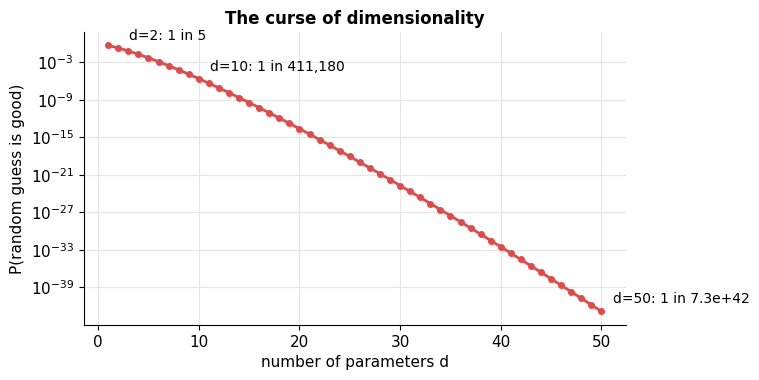

In [4]:
from scipy.special import gammaln
d = np.arange(1, 51)
log_ball = (d / 2) * np.log(np.pi) - gammaln(d / 2 + 1) + d * np.log(0.5)     # volume of a radius-0.5 ball
prob = np.exp(log_ball - d * np.log(2.0))                                      # ÷ volume of the box [-1,1]^d

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.semilogy(d, prob, "o-", color=C["red"], ms=4)
for dd in [2, 10, 50]:
    ax.annotate(f"d={dd}: 1 in {1/prob[dd-1]:,.0f}" if dd < 50 else f"d=50: 1 in {1/prob[dd-1]:.1e}",
                (dd, prob[dd - 1]), xytext=(8, 6), textcoords="offset points", fontsize=10)
ax.set(xlabel="number of parameters d", ylabel="P(random guess is good)", title="The curse of dimensionality")
plt.show()

With 50 parameters you'd need about $10^{28}$ guesses. A small neural network has a million. We need **guidance**.

---
## 4. Optimality conditions: what does the bottom look like?

If $f$ is differentiable and $\theta^*$ is a minimum, the ground is **flat** there:

$$\nabla f(\theta^*) = 0 \qquad \text{(the first-order necessary condition)}$$

Points where $\nabla f = 0$ are called **stationary points**. But, as the lecture warns, **not all stationary points are optimal**: tops of hills and saddles are flat too. The **second derivative** (in many dimensions, the **Hessian** matrix $\nabla^2 f$) tells them apart. This is notebook 01's bowl vs. saddle:

| Hessian at a stationary point | It's a... |
|---|---|
| positive definite (all eigenvalues > 0) | local **minimum** (bowl) |
| negative definite (all < 0) | local **maximum** (dome) |
| mixed signs | **saddle point** |

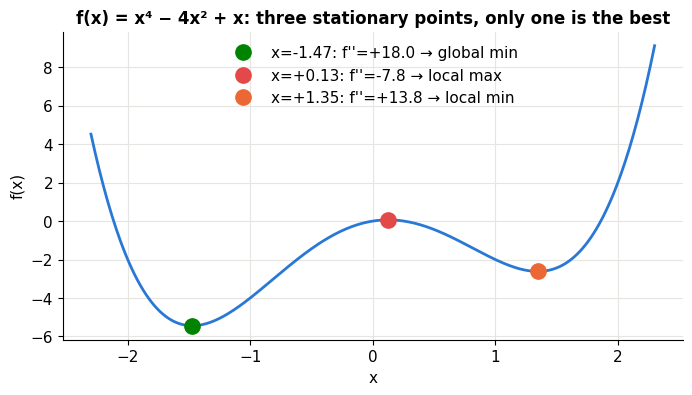

In [5]:
f1 = lambda x: x**4 - 4 * x**2 + x
df1 = lambda x: 4 * x**3 - 8 * x + 1
d2f1 = lambda x: 12 * x**2 - 8
roots = np.sort(np.roots([4, 0, -8, 1]).real)                  # solve f'(x) = 0

xx = np.linspace(-2.3, 2.3, 400)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(xx, f1(xx), color=C["blue"])
for r in roots:
    kind, col = (("global min", C["green"]) if f1(r) == min(f1(roots)) else ("local min", C["orange"])) if d2f1(r) > 0 \
                else ("local max", C["red"])
    ax.plot(r, f1(r), "o", color=col, ms=11, label=f"x={r:+.2f}: f''={d2f1(r):+.1f} → {kind}")
ax.set(xlabel="x", ylabel="f(x)", title="f(x) = x⁴ − 4x² + x: three stationary points, only one is the best")
ax.legend(loc="upper center"); plt.show()

For some problems you can just **solve** $\nabla f = 0$. Least squares is the classic case (CX 4240 Lecture 4, and derived in notebook 01):

$$f(\theta) = \|X\theta - y\|^2 \;\Rightarrow\; \nabla f = 2X^\top(X\theta - y) = 0 \;\Rightarrow\; \theta^* = (X^\top X)^{-1}X^\top y$$

**But what if the optimality condition is too hard to solve?** For logistic regression, neural networks and almost everything else, $\nabla f = 0$ has no closed-form solution. That's where iterative methods come in.

---
## 5. Local search: feel around with your feet

Back to the hiker. Instead of teleporting, they **probe a few spots nearby and step to the lowest one**. Repeat. This uses local information, which is a big improvement.

In [6]:
def local_search(f, x0, radius=0.4, probes=8, steps=40, seed=3):
    r = np.random.default_rng(seed)
    x = np.array(x0, float); path = [x.copy()]
    for _ in range(steps):
        ang = r.uniform(0, 2 * np.pi, probes)
        cand = x + radius * np.column_stack([np.cos(ang), np.sin(ang)])
        best = cand[np.argmin(f(cand.T))]
        if f(best) < f(x):
            x = best
        path.append(x.copy())
    return np.array(path)

ls_path = local_search(himmelblau, (-0.5, -4.5))
fig, ax = plt.subplots(figsize=(5.5, 5), dpi=72)
contour(ax, himmelblau, (-5, 5), (-5, 5), log=True)
trail, = ax.plot([], [], "-o", color=C["orange"], ms=3)
probe_circle = plt.Circle((0, 0), 0.4, fill=False, color=C["yellow"], lw=2)
ax.add_patch(probe_circle)
title = ax.set_title("step 000: loss = 000.00")
fig.tight_layout()

def frame(k):
    trail.set_data(ls_path[:k + 1, 0], ls_path[:k + 1, 1]); probe_circle.center = ls_path[k]
    title.set_text(f"step {k}: loss = {himmelblau(ls_path[k]):.2f}")
    return trail, probe_circle

show_anim(animation.FuncAnimation(fig, frame, frames=len(ls_path), interval=120))

Better: it walks steadily downhill. But notice it **stalls near the bottom without reaching it**, because probes at a fixed radius of 0.4 are too coarse to find the last bit of improvement. And probing is wasteful: each step costs several function evaluations, most of which are thrown away, and in $d$ dimensions you'd need many probes to find a good direction. What if the ground could simply *tell us* which way is downhill?

---
## 6. Gradient descent

### Where the update comes from

Near the current point $\theta$, a smooth function looks like a tilted plane (first-order Taylor expansion):

$$f(\theta + \Delta) \approx f(\theta) + \nabla f(\theta)^\top \Delta$$

We want to choose a small step $\Delta$ that decreases $f$ as much as possible. The change is the dot product $\nabla f^\top\Delta = \|\nabla f\|\|\Delta\|\cos\alpha$ (notebook 01!). For a fixed step length, it's most negative when $\cos\alpha = -1$, i.e. $\Delta$ points **exactly opposite the gradient**. The gradient points uphill; we go the other way:

$$\boxed{\theta_{t+1} = \theta_t - \eta\,\nabla f(\theta_t)}$$

$\eta > 0$ is the **learning rate** (step size). That's the whole algorithm:

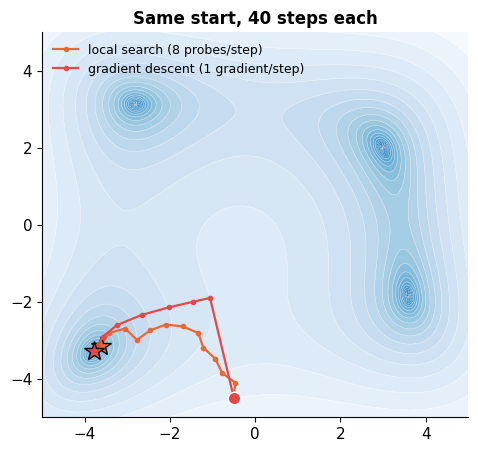

In [7]:
def gradient_descent(grad, x0, lr, steps):
    x = np.array(x0, float)
    path = [x.copy()]
    for _ in range(steps):
        x = x - lr * grad(x)        # ← the entire algorithm
        path.append(x.copy())
    return np.array(path)

gd_path = gradient_descent(himmelblau_g, (-0.5, -4.5), lr=0.01, steps=40)
fig, ax = plt.subplots(figsize=(5.5, 5))
contour(ax, himmelblau, (-5, 5), (-5, 5), log=True)
plot_path(ax, ls_path, C["orange"], "local search (8 probes/step)")
plot_path(ax, gd_path, C["red"], "gradient descent (1 gradient/step)")
ax.legend(loc="upper left", fontsize=9); ax.set_title("Same start, 40 steps each"); plt.show()

### The learning rate is everything

Take the simplest possible case, $f(x) = \frac{a}{2}x^2$ with gradient $ax$. One GD step gives

$$x_{t+1} = x_t - \eta a x_t = (1 - \eta a)\,x_t \quad\Longrightarrow\quad x_t = (1-\eta a)^t x_0$$

So GD converges **if and only if $|1 - \eta a| < 1$, i.e. $0 < \eta < 2/a$**. The curvature $a$ sets the speed limit:

| $\eta$ | behavior |
|---|---|
| $\eta \ll 1/a$ | crawls |
| $\eta = 1/a$ | jumps to the minimum in one step |
| $1/a < \eta < 2/a$ | overshoots and oscillates, but converges |
| $\eta > 2/a$ | **diverges**: every step overshoots further |

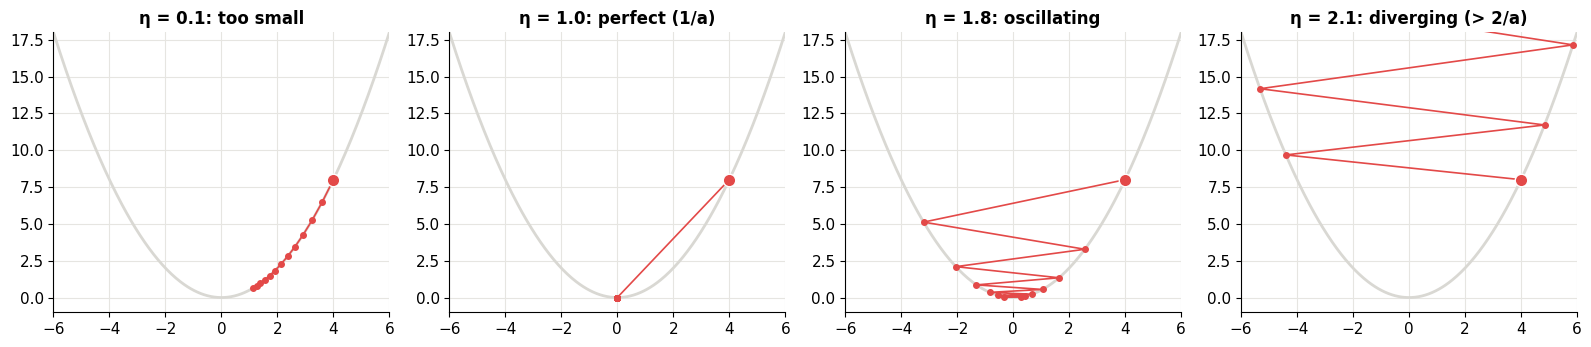

In [8]:
fq = lambda x: 0.5 * x**2                                  # a = 1, so the threshold is η = 2
xx = np.linspace(-6, 6, 300)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, lr, name in zip(axes, [0.1, 1.0, 1.8, 2.1], ["too small", "perfect (1/a)", "oscillating", "diverging (> 2/a)"]):
    path = [4.0]
    for _ in range(12):
        path.append(path[-1] - lr * path[-1])
    path = np.array(path)
    ax.plot(xx, fq(xx), color=C["light"])
    ax.plot(path, fq(path), "-o", color=C["red"], ms=4, lw=1.2)
    ax.plot(path[0], fq(path[0]), "o", color=C["red"], ms=9, markeredgecolor="white")
    ax.set(ylim=(-1, 18), xlim=(-6, 6), title=f"η = {lr}: {name}")
fig.tight_layout(); plt.show()

### 🎚️ Tune the learning rate in 2-D

The function is an elongated bowl, $f(x, y) = \frac12(x^2 + 10y^2)$. The curvatures are 1 along $x$ and 10 along $y$, so the speed limit is set by the **steepest** direction: $\eta < 2/10 = 0.2$. Try:
- $\eta = 0.02$: slow and steady, still far from the minimum after 30 steps.
- $\eta = 0.15$: fast along $y$ but zig-zagging.
- $\eta = 0.19$: violent zig-zag along $y$ while $x$ improves.
- $\eta = 0.21$: divergence.

In [9]:
A_rav = np.diag([1.0, 10.0])
f_rav = lambda p: 0.5 * (A_rav[0, 0] * p[0]**2 + A_rav[1, 1] * p[1]**2)
g_rav = lambda p: A_rav @ p

def plot_lr(lr=0.1, steps=30):
    path = gradient_descent(g_rav, (-4.5, 1.8), lr, steps)
    path = np.clip(path, -60, 60)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw=dict(width_ratios=[1.6, 1]))
    contour(ax1, f_rav, (-5, 5), (-2.5, 2.5), levels=25)
    plot_path(ax1, path, C["red"])
    ax1.set(aspect="equal", title=f"η = {lr:.3f}")
    losses = [f_rav(p) for p in path]
    ax2.semilogy(losses, color=C["red"]); ax2.set(xlabel="step", ylabel="loss (log)", title=f"final loss = {losses[-1]:.2e}")
    plt.show()

interact(plot_lr, lr=FloatSlider(value=0.1, min=0.005, max=0.215, step=0.005, readout_format=".3f", description="η"),
         steps=IntSlider(value=30, min=5, max=100, description="steps"));

### Why ravines are slow: the condition number

The bowl above has curvatures 1 and 10. The learning rate must be small enough for the steep direction ($\eta < 2/10$), which makes progress along the gentle direction slow. The ratio

$$\kappa = \frac{\lambda_{\max}}{\lambda_{\min}} \quad \text{(eigenvalues of the Hessian)}$$

is the **condition number**. For a quadratic, GD needs roughly $\kappa$ steps to make real progress. The ravine above has $\kappa = 10$; the apartment problem from notebook 00, *without* standardizing, has a much bigger one. That's why we standardized there.

raw area (ft²)       Hessian eigenvalues = [2.540000e-01 1.677965e+06],  condition number κ = 6,609,036
standardized area    Hessian eigenvalues = [2. 2.],  condition number κ = 1


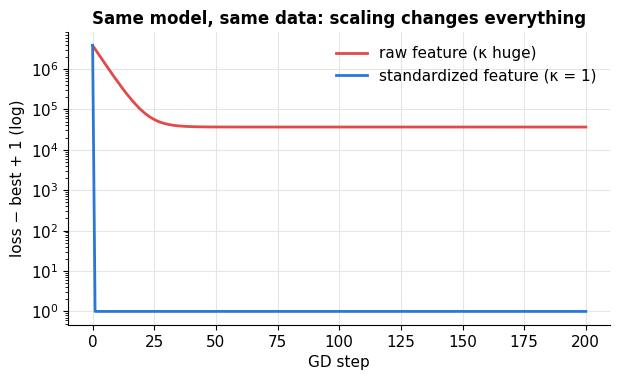

After 200 steps, raw-feature GD has intercept θ0 = 0.0 (the right answer is ≈ 536)


In [10]:
X_raw = np.column_stack([np.ones(n), area])                    # unscaled: intercept + area in ft²
X_std = np.column_stack([np.ones(n), z])                       # standardized area
for name, Xm in [("raw area (ft²)", X_raw), ("standardized area", X_std)]:
    H = 2 * Xm.T @ Xm / n                                      # Hessian of the MSE
    lam = np.linalg.eigvalsh(H)
    print(f"{name:20s} Hessian eigenvalues = {lam.round(3)},  condition number κ = {lam.max()/lam.min():,.0f}")

def gd_linreg(Xm, y, lr, steps):
    th = np.zeros(Xm.shape[1]); path = [th.copy()]
    for _ in range(steps):
        th = th - lr * 2 * Xm.T @ (Xm @ th - y) / len(y); path.append(th.copy())
    return np.array(path)

lam_raw = np.linalg.eigvalsh(2 * X_raw.T @ X_raw / n).max()
p_raw = gd_linreg(X_raw, rent, lr=1.9 / lam_raw, steps=200)
p_std = gd_linreg(X_std, rent, lr=0.5, steps=200)
loss = lambda Xm, P: [np.mean((Xm @ t - rent) ** 2) for t in P]
best = np.mean((X_std @ np.linalg.lstsq(X_std, rent, rcond=None)[0] - rent) ** 2)

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.semilogy(np.array(loss(X_raw, p_raw)) - best + 1, color=C["red"], label="raw feature (κ huge)")
ax.semilogy(np.array(loss(X_std, p_std)) - best + 1, color=C["blue"], label="standardized feature (κ = 1)")
ax.set(xlabel="GD step", ylabel="loss − best + 1 (log)", title="Same model, same data: scaling changes everything")
ax.legend(); plt.show()
print(f"After 200 steps, raw-feature GD has intercept θ0 = {p_raw[-1, 0]:.1f} (the right answer is ≈ {np.linalg.lstsq(X_raw, rent, rcond=None)[0][0]:.0f})")

With the raw feature, the area direction has enormous curvature (area² is around $10^6$), which forces a tiny learning rate, so the intercept barely moves in 200 steps. After standardizing, both directions have the same curvature and GD converges in a handful of steps. **Always standardize your features before gradient-based training.** (Notebook 19 shows that neural networks have their own version: BatchNorm / LayerNorm.)

### Letting the algorithm pick its own step size (the CX 4240 recipe)

Picking $\eta$ by hand is annoying, and the best value changes as you move around the landscape. CX 4240 (Lecture 4, "Gradient Method Summary") uses a simple fix: **try a step; if it helps, be bolder next time; if it hurts, reject it and be more careful.**

> choose $\theta^1$ and $h^1 > 0$ (e.g. $h^1 = 1$)
> for $k = 1, 2, \dots$
> 1. compute $\nabla f(\theta^k)$; quit if $\|\nabla f(\theta^k)\|$ is small enough
> 2. tentative step: $\theta^{\text{tent}} = \theta^k - h^k \nabla f(\theta^k)$
> 3. if $f(\theta^{\text{tent}}) < f(\theta^k)$: **accept**, $\theta^{k+1} = \theta^{\text{tent}}$ and grow $h^{k+1} = 1.2\,h^k$
> 4. else: **reject**, shrink $h^k := 0.5\,h^k$ and go back to step 2

Because a step is only accepted when the loss goes down, this is a **descent method**: $f(\theta^{k+1}) < f(\theta^k)$ at every step. That guarantees the loss converges, though (on non-convex problems) not necessarily to the global minimum $f^*$.

Below, the ravine from before, starting with $h = 1$. That's 5× **over** the divergence threshold of 0.2, so a fixed step size would explode. The adaptive rule shrinks the step until it works, then keeps probing upward.

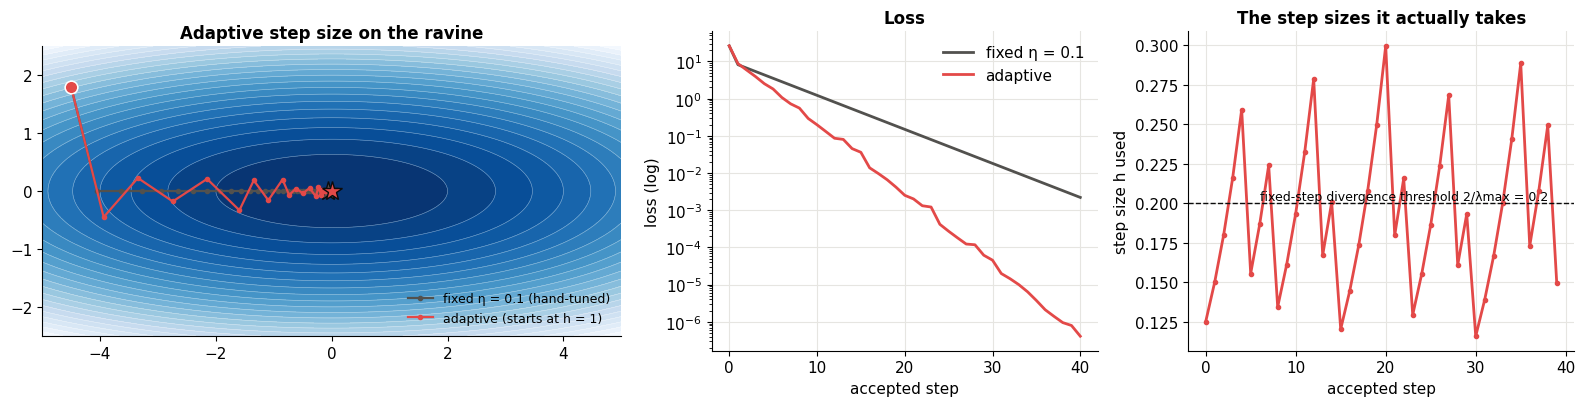

40 accepted steps, 13 rejected tries. Final loss: adaptive 4.10e-07 vs fixed 2.21e-03


In [11]:
def adaptive_gd(f, grad, theta0, h=1.0, steps=40, grow=1.2, shrink=0.5, tol=1e-8):
    """CX 4240's gradient method: accept-and-grow / reject-and-shrink."""
    th = np.array(theta0, float)
    path, hs, rejected = [th.copy()], [], 0
    for _ in range(steps):
        g = grad(th)
        if np.linalg.norm(g) < tol:
            break
        while True:
            tent = th - h * g
            if f(tent) < f(th):          # it helped: accept and be bolder
                hs.append(h)             # record the step size actually used
                th, h = tent, grow * h
                break
            h *= shrink                  # it hurt: reject and be more careful
            rejected += 1
        path.append(th.copy())
    return np.array(path), np.array(hs), rejected

ad_path, ad_h, n_rej = adaptive_gd(f_rav, g_rav, (-4.5, 1.8), h=1.0, steps=40)
fx_path = gradient_descent(g_rav, (-4.5, 1.8), 0.1, 40)          # a hand-tuned fixed step, for comparison

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 4.2), gridspec_kw=dict(width_ratios=[1.5, 1, 1]))
contour(ax1, f_rav, (-5, 5), (-2.5, 2.5), levels=25)
plot_path(ax1, fx_path, C["muted"], "fixed η = 0.1 (hand-tuned)")
plot_path(ax1, ad_path, C["red"], "adaptive (starts at h = 1)")
ax1.set(aspect="equal", title="Adaptive step size on the ravine"); ax1.legend(fontsize=9, loc="lower right")
ax2.semilogy([f_rav(p) for p in fx_path], color=C["muted"], label="fixed η = 0.1")
ax2.semilogy([f_rav(p) for p in ad_path], color=C["red"], label="adaptive")
ax2.set(xlabel="accepted step", ylabel="loss (log)", title="Loss"); ax2.legend()
ax3.plot(ad_h, "-o", color=C["red"], ms=3)
ax3.axhline(0.2, color=C["ink"], ls="--", lw=1)
ax3.text(len(ad_h) - 1, 0.2, "fixed-step divergence threshold 2/λmax = 0.2  ", fontsize=9, ha="right", va="bottom")
ax3.set(xlabel="accepted step", ylabel="step size h used", title="The step sizes it actually takes")
fig.tight_layout(); plt.show()
print(f"{len(ad_path)-1} accepted steps, {n_rej} rejected tries. Final loss: adaptive {f_rav(ad_path[-1]):.2e} vs fixed {f_rav(fx_path[-1]):.2e}")

Notice the right panel: the step size **hovers right around the edge of stability**, growing until a step fails, then halving. With no tuning at all it beats a hand-picked learning rate.

Some accepted steps are even *above* 0.2. That's not a contradiction: the threshold says that **repeating** a step of that size forever diverges. A single bold step can still lower the loss, and the rule only keeps steps that do. Mixing bold and careful steps is part of why it converges faster than any single fixed $\eta$ here.

> 🤔 **Question: Why don't deep learning libraries do this?**
>
> Checking whether $f(\theta^{\text{tent}}) < f(\theta^k)$ requires evaluating the loss on **the whole dataset**, which is exactly what SGD (section 8) avoids. On a noisy mini-batch, the loss can go up even after a good step. So deep learning uses fixed or scheduled learning rates plus adaptive optimizers like Adam (section 9) instead. The accept/reject idea lives on in classical optimizers (line searches in L-BFGS, which `scipy.optimize.minimize` uses), and its "edge of stability" behavior is a real phenomenon in neural network training.

### When do we stop?

Common stopping criteria, usually combined:
- the gradient is tiny: $\|\nabla f(\theta_t)\| < \epsilon$,
- the loss stopped improving: $|f(\theta_{t}) - f(\theta_{t-1})| < \epsilon$,
- a maximum number of steps (or a time budget),
- in ML, **early stopping**: the loss on held-out *validation* data starts rising (notebook 06).

### How fast does it converge? (the theory, briefly)

For a **convex** function whose gradient doesn't change too abruptly ($L$-smooth), GD with $\eta = 1/L$ satisfies $f(\theta_t) - f^* \le \frac{L\|\theta_0 - \theta^*\|^2}{2t}$: error shrinks like $1/t$. If the function is also **strongly convex** (curvature at least $\mu > 0$ everywhere), the error shrinks *geometrically*, like $(1 - \mu/L)^t = (1 - 1/\kappa)^t$. That's the condition number again.

---
## 7. Convex vs. non-convex

A function is **convex** if the straight line between any two points on its graph never dips below the graph:

$$f\big(\lambda a + (1-\lambda) b\big) \le \lambda f(a) + (1-\lambda) f(b) \quad \text{for all } a, b, \; \lambda\in[0,1]$$

For twice-differentiable functions this is equivalent to: **the Hessian is PSD everywhere** (bowl-shaped everywhere).

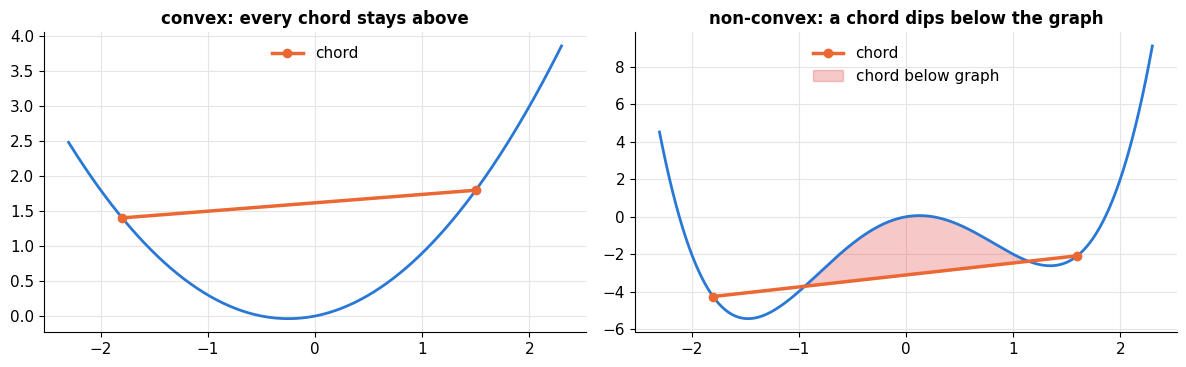

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
xx = np.linspace(-2.3, 2.3, 300)
for ax, (f, name, (a, b)) in zip(axes, [(lambda x: 0.6 * x**2 + 0.3 * x, "convex: every chord stays above", (-1.8, 1.5)),
                                         (f1, "non-convex: a chord dips below the graph", (-1.8, 1.6))]):
    ax.plot(xx, f(xx), color=C["blue"])
    lam = np.linspace(0, 1, 50); cx = lam * a + (1 - lam) * b
    ax.plot([a, b], [f(a), f(b)], "o-", color=C["orange"], lw=2.5, label="chord")
    below = (lam * f(a) + (1 - lam) * f(b)) < f(cx) - 1e-9
    if below.any():
        ax.fill_between(cx, lam * f(a) + (1 - lam) * f(b), f(cx), where=below, color=C["red"], alpha=0.3, label="chord below graph")
    ax.set_title(name); ax.legend(loc="upper center")
fig.tight_layout(); plt.show()

**Why convexity matters so much:** for a convex function, **every local minimum is a global minimum**. Any stationary point is the answer, and gradient descent (with a sensible learning rate) can't get stuck. Linear regression, logistic regression, Lasso and SVMs are convex. Neural networks are **not**.

> 🤔 **Question: How can you tell if a loss is convex?**
>
> Check the Hessian. For MSE in linear regression, $\nabla^2 f = \frac{2}{n} X^\top X$, which is PSD (notebook 01), so it's convex. Useful rules: sums of convex functions are convex, a convex function of a linear function ($f(X\theta)$) is convex, and the max of convex functions is convex. ISYE 4600 HW3 uses these to prove logistic regression's loss is convex.

### 🎬 Non-convex: where you start decides where you end

Eight gradient-descent runs on Himmelblau's function, from random starting points. They end in different valleys.

In [13]:
starts = rng.uniform(-4.5, 4.5, size=(8, 2))
paths = [gradient_descent(himmelblau_g, s, lr=0.008, steps=60) for s in starts]
colors = [C[k] for k in ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]

fig, ax = plt.subplots(figsize=(5.5, 5), dpi=72)
contour(ax, himmelblau, (-5, 5), (-5, 5), log=True)
lines = [ax.plot([], [], "-", color=c, lw=2)[0] for c in colors]
heads = [ax.plot([], [], "o", color=c, ms=8, markeredgecolor="white")[0] for c in colors]
title = ax.set_title("step 000: loss = 000.00"); fig.tight_layout()

def frame(k):
    for p, ln, hd in zip(paths, lines, heads):
        ln.set_data(p[:k + 1, 0], p[:k + 1, 1]); hd.set_data([p[k, 0]], [p[k, 1]])
    title.set_text(f"step {k}")
    return lines + heads

show_anim(animation.FuncAnimation(fig, frame, frames=range(0, 61, 2), interval=150))

🎚️ **Pick your own starting point** and see which valley you fall into. (Himmelblau's four minima all have loss exactly 0, so here every valley is equally good. In real problems they usually aren't.)

In [14]:
def plot_start(x0=0.0, y0=0.0, lr=0.008):
    path = gradient_descent(himmelblau_g, (x0, y0), lr, 80)
    fig, ax = plt.subplots(figsize=(5.2, 5))
    contour(ax, himmelblau, (-5, 5), (-5, 5), log=True)
    plot_path(ax, np.clip(path, -5, 5), C["red"])
    ax.set_title(f"ends at ({path[-1,0]:.2f}, {path[-1,1]:.2f}), loss {himmelblau(path[-1]):.2e}")
    plt.show()

interact(plot_start, x0=FloatSlider(value=0, min=-5, max=5, step=0.1, description="x₀"),
         y0=FloatSlider(value=0, min=-5, max=5, step=0.1, description="y₀"),
         lr=FloatSlider(value=0.008, min=0.001, max=0.03, step=0.001, readout_format=".3f", description="η"));

### Saddle points: the real enemy in high dimensions

In high dimensions, most stationary points are **saddles**, not local minima. (For a random Hessian, "all eigenvalues positive" becomes very unlikely as $d$ grows.) Gradient descent isn't trapped by a saddle, but it **slows to a crawl** near one because the gradient is almost zero. That's the long plateaus you'll see in neural-network loss curves.

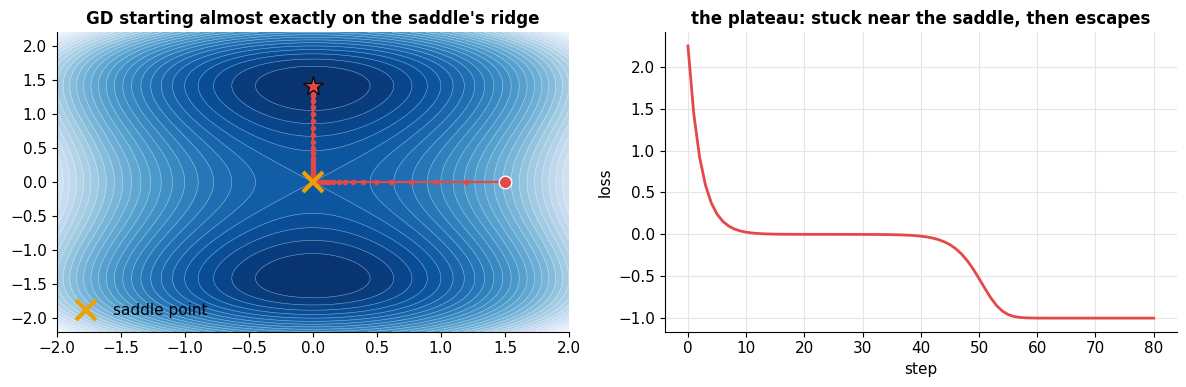

In [15]:
f_sad = lambda p: p[0]**2 - p[1]**2 + 0.25 * p[1]**4        # saddle at (0,0), minima at y = ±√2
g_sad = lambda p: np.array([2 * p[0], -2 * p[1] + p[1]**3])
path = gradient_descent(g_sad, (1.5, 1e-4), lr=0.1, steps=80)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
contour(ax1, lambda p: f_sad(p) + 1.2, (-2, 2), (-2.2, 2.2), levels=30)
plot_path(ax1, path, C["red"]); ax1.plot(0, 0, "x", color=C["yellow"], ms=14, mew=3, label="saddle point")
ax1.legend(loc="lower left"); ax1.set_title("GD starting almost exactly on the saddle's ridge")
ax2.plot([f_sad(p) for p in path], color=C["red"])
ax2.set(xlabel="step", ylabel="loss", title="the plateau: stuck near the saddle, then escapes")
fig.tight_layout(); plt.show()

---
## 8. Stochastic gradient descent (SGD)

The loss is an **average over the dataset**, so its gradient is too:

$$\nabla f(\theta) = \frac{1}{n}\sum_{i=1}^{n}\nabla \ell_i(\theta)$$

With $n$ = millions of examples, computing that exact average for every single step is extremely expensive. **SGD's idea: estimate the average from a small random mini-batch $B$**, as in notebook 02's Monte Carlo:

$$\nabla f(\theta) \approx \frac{1}{|B|}\sum_{i \in B}\nabla \ell_i(\theta)$$

The estimate is **unbiased** (correct on average) but **noisy**, with noise variance shrinking like $1/|B|$ (the CLT again). You get a slightly wrong direction, but $n/|B|$ times cheaper.

Let's look at the individual per-example gradients for a linear regression with 2 parameters:

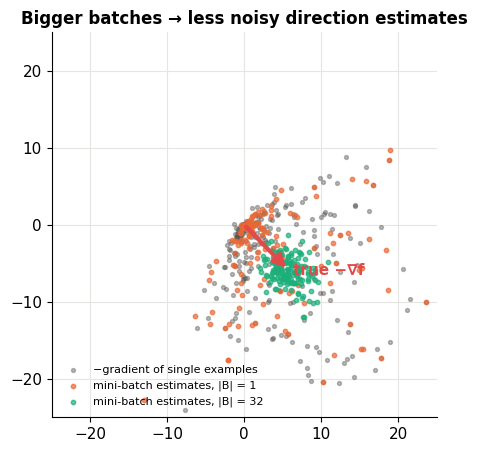

In [16]:
N = 2000
Xs = rng.normal(size=(N, 2))
theta_true = np.array([2.0, -1.0])
ys = Xs @ theta_true + rng.normal(0, 1.0, N)
# MSE(θ) = θᵀSθ − 2θᵀb + c, with S = XᵀX/N, b = Xᵀy/N, c = yᵀy/N (cheap to evaluate on a whole grid)
S_, b_, c_ = Xs.T @ Xs / N, Xs.T @ ys / N, ys @ ys / N
f_lr = lambda p: (S_[0, 0] * p[0]**2 + 2 * S_[0, 1] * p[0] * p[1] + S_[1, 1] * p[1]**2
                  - 2 * (b_[0] * p[0] + b_[1] * p[1]) + c_)
grad_i = lambda th, idx: -2 * Xs[idx] * (ys[idx] - Xs[idx] @ th)[:, None]     # one gradient per example

th0 = np.array([-1.0, 2.0])
G = grad_i(th0, np.arange(N))
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(*(-G[:300]).T, s=8, color=C["muted"], alpha=0.4, label="−gradient of single examples")
for bs, col in [(1, C["orange"]), (32, C["aqua"])]:
    est = np.array([G[rng.choice(N, bs)].mean(0) for _ in range(150)])
    ax.scatter(*(-est).T, s=10, color=col, alpha=0.7, label=f"mini-batch estimates, |B| = {bs}")
ax.annotate("", xy=-G.mean(0), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=C["red"], lw=3, mutation_scale=18))
ax.text(*(-G.mean(0) * 1.1), "true −∇f", color=C["red"], weight="bold")
ax.set(aspect="equal", xlim=(-25, 25), ylim=(-25, 25), title="Bigger batches → less noisy direction estimates")
ax.legend(loc="lower left", fontsize=8); plt.show()

Single-example gradients point all over the place, but on average they point the right way. A batch of 32 is already a decent estimate.

### 🎚️ GD vs. SGD

Each path below processes the **same total number of examples** (5 passes over the data, called **epochs**). Full-batch GD takes only 5 careful steps. SGD with batch size $|B|$ takes $5n/|B|$ cheap, noisy steps. Drag the batch size and learning rate.

In [17]:
def sgd(theta0, lr, batch_size, epochs, decay=False, seed=0):
    r = np.random.default_rng(seed)
    th = np.array(theta0, float); path = [th.copy()]; t = 0
    for ep in range(epochs):
        perm = r.permutation(N)                       # shuffle each epoch
        for s in range(0, N, batch_size):
            idx = perm[s:s + batch_size]
            step = lr / (1 + 0.02 * t) if decay else lr
            th = th - step * grad_i(th, idx).mean(0)
            path.append(th.copy()); t += 1
    return np.array(path)

def plot_sgd(batch_size=32, lr=0.05):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6))
    contour(ax1, f_lr, (-1.5, 3), (-2, 2.5), levels=25)
    p_gd = sgd(th0, 0.3, N, 5); p_sgd = sgd(th0, lr, batch_size, 5)
    ax1.plot(*p_sgd.T, "-", color=C["orange"], lw=1, alpha=0.8, label=f"SGD |B|={batch_size} ({len(p_sgd)-1} steps)")
    plot_path(ax1, p_gd, C["red"], "full-batch GD (5 steps)", ms=6)
    ax1.plot(*theta_true, "P", color=C["ink"], ms=12, label="true θ")
    ax1.legend(loc="upper right", fontsize=8); ax1.set(aspect="equal", title="paths")
    ex = lambda P, bs: np.arange(len(P)) * bs
    ax2.semilogy(ex(p_gd, N), [f_lr(p) for p in p_gd], "o-", color=C["red"], label="GD")
    ax2.semilogy(ex(p_sgd, batch_size), [f_lr(p) for p in p_sgd], color=C["orange"], label="SGD")
    ax2.set(xlabel="examples processed (compute)", ylabel="loss (log)", title="loss vs. compute"); ax2.legend()
    plt.show()

interact(plot_sgd, batch_size=widgets.SelectionSlider(options=[1, 4, 16, 32, 128, 512], value=32, description="|B|"),
         lr=FloatSlider(value=0.05, min=0.005, max=0.3, step=0.005, readout_format=".3f", description="η"));

SGD reaches a good loss after seeing only a fraction of the data, long before full-batch GD has taken its second step. That's why every neural network is trained with mini-batch SGD or one of its descendants.

### The noise ball and learning-rate decay

With a constant learning rate, SGD never fully settles. It keeps bouncing around the minimum in a "noise ball" whose size is proportional to $\eta$. Shrinking $\eta$ over time (a **learning-rate schedule**) lets it settle down.

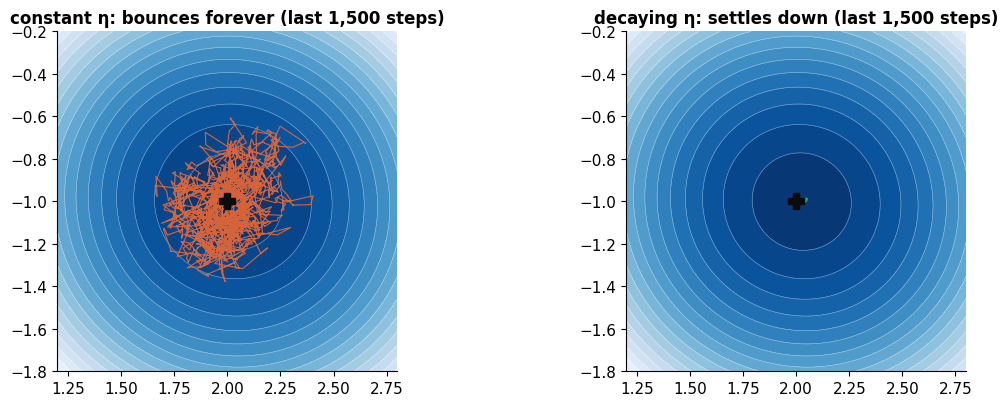

In [18]:
const = sgd((2.6, -0.2), lr=0.02, batch_size=1, epochs=2, seed=1)
decay = sgd((2.6, -0.2), lr=0.02, batch_size=1, epochs=2, decay=True, seed=1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, P, name, col in [(ax1, const, "constant η: bounces forever", C["orange"]), (ax2, decay, "decaying η: settles down", C["aqua"])]:
    contour(ax, f_lr, (1.2, 2.8), (-1.8, -0.2), levels=20)
    ax.plot(*P[-1500:].T, "-", color=col, lw=0.8, alpha=0.9)
    ax.plot(*theta_true, "P", color=C["ink"], ms=12)
    ax.set(aspect="equal", title=name + " (last 1,500 steps)")
fig.tight_layout(); plt.show()

> 🤔 **Question: How do I choose the batch size?**
>
> In practice it's mostly set by **hardware**: as large as fits in GPU memory makes each step efficient. Typical values are 32–4096 (LLMs use millions of tokens per batch). Smaller batches give noisier gradients, which can actually help generalization a little by acting as a regularizer. A useful rule of thumb: if you double the batch size, you can roughly double the learning rate.

---
## 9. Momentum, RMSProp and Adam

Plain (S)GD has two weaknesses we've already seen: it **zig-zags in ravines** and it **crawls on plateaus**. The fixes:

**Momentum**: a heavy ball rolling downhill. Keep a running "velocity" that accumulates gradients:
$$v_{t} = \beta v_{t-1} + \nabla f(\theta_t), \qquad \theta_{t+1} = \theta_t - \eta\, v_t$$
Oscillating components cancel out across steps, while consistent ones add up and accelerate. Typical $\beta = 0.9$.

**RMSProp**: give each parameter its own step size. Track the recent average of squared gradients, and divide by its square root:
$$s_t = \rho s_{t-1} + (1-\rho)\,\big(\nabla f(\theta_t)\big)^2, \qquad \theta_{t+1} = \theta_t - \eta\,\frac{\nabla f(\theta_t)}{\sqrt{s_t} + \epsilon}$$
Steep directions get smaller steps, flat ones get bigger steps: an automatic fix for bad conditioning.

**Adam** = momentum + RMSProp + a "bias correction" for the first few steps:
$$m_t = \beta_1 m_{t-1} + (1-\beta_1) g_t, \quad s_t = \beta_2 s_{t-1} + (1-\beta_2) g_t^2, \quad \hat m_t = \frac{m_t}{1-\beta_1^t},\; \hat s_t = \frac{s_t}{1-\beta_2^t}, \quad \theta_{t+1} = \theta_t - \eta\frac{\hat m_t}{\sqrt{\hat s_t}+\epsilon}$$
Defaults $\beta_1 = 0.9$, $\beta_2 = 0.999$. Adam (or its variant AdamW) trains essentially every transformer, including GPT.

All of them fit in a few lines:

In [19]:
def optimize(grad, x0, method, lr, steps, beta=0.9, beta2=0.999, eps=1e-8):
    x = np.array(x0, float)
    v = np.zeros_like(x)        # momentum / first moment
    s = np.zeros_like(x)        # running average of squared gradients / second moment
    path = [x.copy()]
    for t in range(1, steps + 1):
        g = grad(x)
        if method == "gd":
            x = x - lr * g
        elif method == "momentum":
            v = beta * v + g
            x = x - lr * v
        elif method == "rmsprop":
            s = beta2 * s + (1 - beta2) * g**2
            x = x - lr * g / (np.sqrt(s) + eps)
        elif method == "adam":
            v = beta * v + (1 - beta) * g
            s = beta2 * s + (1 - beta2) * g**2
            v_hat, s_hat = v / (1 - beta**t), s / (1 - beta2**t)      # bias correction
            x = x - lr * v_hat / (np.sqrt(s_hat) + eps)
        path.append(x.copy())
    return np.array(path)

### 🎬 The race: four optimizers on the Rosenbrock "banana"

The Rosenbrock function $f(x,y) = (1-x)^2 + 100(y - x^2)^2$ has its minimum at $(1, 1)$ (the star), at the end of a long, curved, flat-bottomed valley. It's a classic stress test. Each optimizer's learning rate was hand-tuned to give it a fair run (try changing them in the exercises).

In [20]:
x0 = (-1.5, 2.0)
racers = [("GD", "gd", dict(lr=8e-4), C["red"]),
          ("Momentum", "momentum", dict(lr=3e-4, beta=0.9), C["blue"]),
          ("RMSProp", "rmsprop", dict(lr=0.01, beta2=0.9), C["aqua"]),
          ("Adam", "adam", dict(lr=0.05), C["orange"])]
race = {name: optimize(rosen_g, x0, m, steps=2000, **kw) for name, m, kw, _ in racers}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8), dpi=68, gridspec_kw=dict(width_ratios=[1.2, 1]))
contour(ax1, rosen, (-2, 2), (-1, 3), log=True, levels=30)
ax1.plot(1, 1, "*", color=C["yellow"], ms=20, markeredgecolor=C["ink"])
trails = {nm: ax1.plot([], [], "-", color=col, lw=2, label=nm)[0] for nm, _, _, col in racers}
dots = {nm: ax1.plot([], [], "o", color=col, ms=8, markeredgecolor="white")[0] for nm, _, _, col in racers}
curves = {nm: ax2.semilogy([], [], color=col, label=nm)[0] for nm, _, _, col in racers}
ax1.legend(loc="upper left", fontsize=9)
ax2.set(xlim=(0, 2000), ylim=(1e-6, 30), xlabel="step", ylabel="loss (log)", title="loss")
title = ax1.set_title("step 0000"); fig.tight_layout()

def frame(k):
    t = int(2000 * (k / 59) ** 1.5)                      # slow-motion start, faster later
    for nm, P in race.items():
        trails[nm].set_data(P[:t + 1, 0], P[:t + 1, 1]); dots[nm].set_data([P[t, 0]], [P[t, 1]])
        curves[nm].set_data(np.arange(t + 1), [rosen(p) for p in P[:t + 1]])
    title.set_text(f"step {t}")
    return list(trails.values()) + list(dots.values()) + list(curves.values())

show_anim(animation.FuncAnimation(fig, frame, frames=60, interval=110))

In [21]:
for nm, P in race.items():
    print(f"{nm:9s} after 2000 steps: ({P[-1,0]:+.3f}, {P[-1,1]:+.3f}),  loss = {rosen(P[-1]):.2e}")

GD        after 2000 steps: (+0.311, +0.094),  loss = 4.75e-01
Momentum  after 2000 steps: (+0.950, +0.903),  loss = 2.46e-03
RMSProp   after 2000 steps: (+0.937, +0.893),  loss = 2.43e-02
Adam      after 2000 steps: (+1.000, +1.000),  loss = 1.73e-12


Plain GD is limited by the steep valley walls and barely makes it down the valley. Momentum builds speed along the valley floor. RMSProp and Adam rescale each direction so the flat valley floor gets bigger steps.

🎚️ **Momentum on the ravine.** Back to the elongated bowl from section 6. Increase $\beta$ from 0 (plain GD) and watch the zig-zag dampen, until too much momentum makes it overshoot like a ball rolling past the bottom.

In [22]:
def plot_momentum(beta=0.0, lr=0.15):
    p = optimize(g_rav, (-4.5, 1.8), "momentum", lr=lr * (1 - beta), steps=40, beta=beta)   # (1−β) keeps step scale comparable
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw=dict(width_ratios=[1.6, 1]))
    contour(ax1, f_rav, (-5, 5), (-2.5, 2.5), levels=25)
    plot_path(ax1, np.clip(p, -50, 50), C["blue"]); ax1.set(aspect="equal", title=f"momentum β = {beta:.2f}")
    ax2.semilogy([f_rav(q) for q in p], color=C["blue"]); ax2.set(xlabel="step", ylabel="loss (log)", ylim=(1e-8, 1e3))
    plt.show()

interact(plot_momentum, beta=FloatSlider(value=0.0, min=0.0, max=0.95, step=0.05, description="β"),
         lr=FloatSlider(value=0.15, min=0.02, max=0.19, step=0.01, description="η"));

> 🤔 **Question: If Adam is so good, why does anyone still use plain SGD (with momentum)?**
>
> Adam is the default for transformers and is very forgiving of the learning rate. But for some tasks, notably image classification with CNNs, well-tuned SGD + momentum often **generalizes slightly better**. Adam also stores two extra numbers per parameter, which matters for memory in huge models. Notebook 20 compares them on a real network.

> 🤔 **Question: What's AdamW?**
>
> Adam with **decoupled weight decay**: instead of adding $\lambda\|\theta\|^2$ to the loss (whose gradient then gets rescaled by Adam's $\sqrt{\hat s}$), it shrinks the weights directly each step, $\theta \leftarrow \theta - \eta\lambda\theta$. This makes regularization behave as intended, and it's what GPT-style models use.

---
## 10. Constrained optimization: Lagrange multipliers and KKT

Sometimes the parameters must satisfy constraints: an SVM's margin conditions (notebook 11), a budget $\|\theta\|_1 \le t$ (Lasso), probabilities summing to 1.

### Equality constraints: the tangency picture

Minimize $f(x, y) = x^2 + 2y^2$ subject to $g(x,y) = x + y - 1 = 0$. Walk along the constraint line. At the best feasible point, the contour of $f$ just **touches** the line without crossing it. Two curves that touch are tangent, so their normal vectors are parallel:

$$\nabla f(x^*) = \lambda \nabla g(x^*)$$

$\lambda$ is the **Lagrange multiplier**. Equivalently, find stationary points of the **Lagrangian** $\mathcal{L}(x, \lambda) = f(x) - \lambda\, g(x)$. Here: $2x = \lambda$, $4y = \lambda$, $x + y = 1$ $\Rightarrow$ $x^* = 2/3$, $y^* = 1/3$.

🎚️ **Slide along the constraint.** The red arrow is $\nabla f$ and the green arrow is $\nabla g$. Find where they line up: that's the constrained minimum.

In [23]:
f_c = lambda p: p[0]**2 + 2 * p[1]**2
def plot_lagrange(t=-0.5):
    P = np.array([t, 1 - t])
    gf = np.array([2 * P[0], 4 * P[1]]); gg = np.array([1.0, 1.0])
    fig, ax = plt.subplots(figsize=(5.5, 5.2))
    xs_ = np.linspace(-2, 2, 300); Xg, Yg = np.meshgrid(xs_, xs_)
    ax.contour(Xg, Yg, f_c(np.stack([Xg, Yg])), levels=20, cmap="Blues_r", linewidths=1)
    ax.contour(Xg, Yg, f_c(np.stack([Xg, Yg])), levels=[f_c(P)], colors=C["blue"], linewidths=2.5)
    ax.plot(xs_, 1 - xs_, color=C["ink"], lw=2, label="constraint x + y = 1")
    ax.annotate("", xy=P + 0.35 * gf / np.linalg.norm(gf), xytext=P, arrowprops=dict(arrowstyle="-|>", color=C["red"], lw=3, mutation_scale=16))
    ax.annotate("", xy=P + 0.35 * gg / np.linalg.norm(gg), xytext=P, arrowprops=dict(arrowstyle="-|>", color=C["green"], lw=3, mutation_scale=16))
    ax.plot(*P, "o", color=C["orange"], ms=10)
    ax.plot(2/3, 1/3, "*", color=C["yellow"], ms=16, markeredgecolor=C["ink"])
    cosang = gf @ gg / np.linalg.norm(gf) / np.linalg.norm(gg)
    ax.set(xlim=(-2, 2), ylim=(-2, 2), aspect="equal", title=f"f = {f_c(P):.3f},  angle(∇f, ∇g) = {np.degrees(np.arccos(np.clip(cosang, -1, 1))):.1f}°")
    ax.legend(loc="lower left"); ax.grid(False); plt.show()

interact(plot_lagrange, t=FloatSlider(value=-0.5, min=-1.2, max=2.0, step=0.02, description="position"));

### Inequality constraints: the KKT conditions

For $\min f(x)$ subject to $g_j(x) \le 0$, the **Karush–Kuhn–Tucker (KKT) conditions** generalize Lagrange. With multipliers $\mu_j$, at the optimum:

1. **Stationarity:** $\nabla f(x^*) + \sum_j \mu_j \nabla g_j(x^*) = 0$
2. **Primal feasibility:** $g_j(x^*) \le 0$
3. **Dual feasibility:** $\mu_j \ge 0$
4. **Complementary slackness:** $\mu_j\, g_j(x^*) = 0$, so for each constraint, *either* it's active ($g_j = 0$, the fence is touched) *or* its multiplier is zero (the fence doesn't matter).

For convex problems these conditions are not just necessary but sufficient. Two cases of $\min (x-2)^2 + (y-1)^2$:

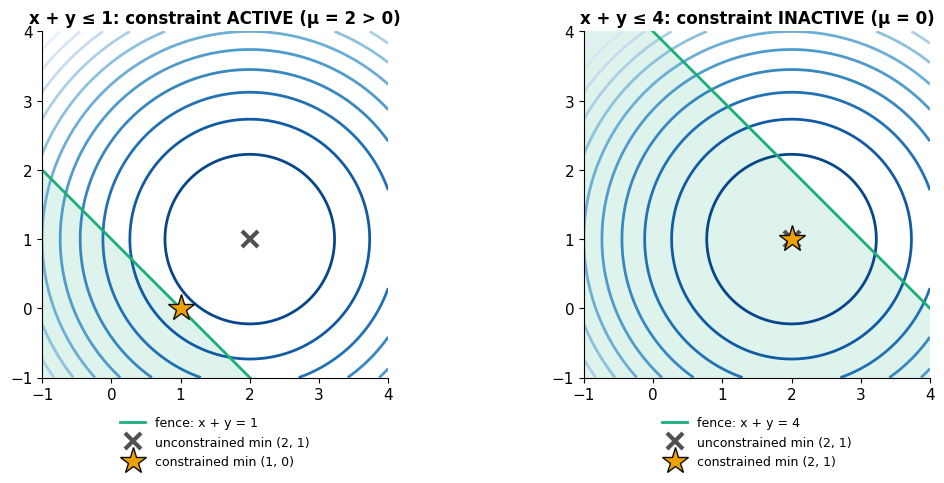

In [24]:
f_k = lambda p: (p[0] - 2)**2 + (p[1] - 1)**2
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, (b, name) in zip(axes, [(1, "x + y ≤ 1: constraint ACTIVE (μ = 2 > 0)"), (4, "x + y ≤ 4: constraint INACTIVE (μ = 0)")]):
    xs_ = np.linspace(-1, 4, 300); Xg, Yg = np.meshgrid(xs_, xs_)
    ax.contour(Xg, Yg, f_k(np.stack([Xg, Yg])), levels=15, cmap="Blues_r")
    ax.contourf(Xg, Yg, (Xg + Yg <= b).astype(float), levels=[0.5, 1.5], colors=[C["aqua"]], alpha=0.15)
    ax.plot(xs_, b - xs_, color=C["aqua"], lw=2, label=f"fence: x + y = {b}")
    ax.plot(2, 1, "x", color=C["muted"], ms=12, mew=3, label="unconstrained min (2, 1)")
    opt = (1, 0) if b == 1 else (2, 1)          # projection of (2,1) onto the half-plane
    ax.plot(*opt, "*", color=C["yellow"], ms=20, markeredgecolor=C["ink"], label=f"constrained min {opt}")
    ax.set(xlim=(-1, 4), ylim=(-1, 4), aspect="equal", title=name); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), fontsize=9); ax.grid(False)
fig.tight_layout(); plt.show()

In the left panel, the unconstrained minimum $(2,1)$ is outside the shaded feasible region, so the best we can do is the closest point on the fence, $(1, 0)$. There $\nabla f = (2(1-2), 2(0-1)) = (-2, -2)$ and $\nabla g = (1, 1)$, so stationarity gives $\mu = 2 \ge 0$. In the right panel, the unconstrained minimum is already feasible, the fence is irrelevant, and $\mu = 0$.

> 🤔 **Question: Where will I actually use KKT?**
>
> - **SVMs (notebook 11):** the training points with $\mu_i > 0$ are exactly the ones touching the margin, the **support vectors**. Complementary slackness is why SVMs depend only on a few points.
> - **Lasso and Ridge (notebook 07):** "minimize loss subject to $\|\theta\|\le t$" and "minimize loss $+\lambda\|\theta\|$" are the same problem; $\lambda$ is the Lagrange multiplier of the budget constraint. Here's the picture you'll see again there:

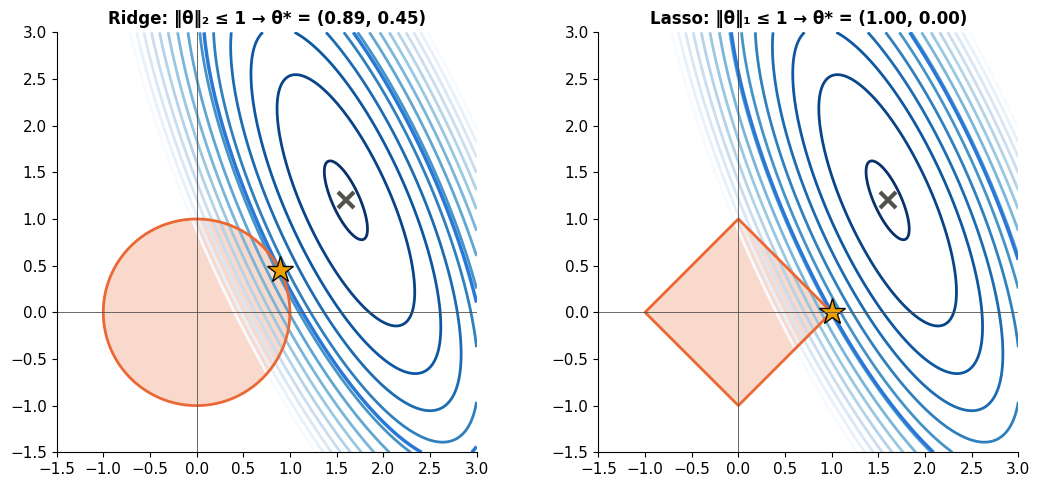

In [25]:
from scipy.optimize import minimize
Q = np.array([[2.0, 0.8], [0.8, 0.6]]); ctr = np.array([1.6, 1.2])
f_ls = lambda p: (p[0] - ctr[0])**2 * Q[0, 0] + 2 * Q[0, 1] * (p[0] - ctr[0]) * (p[1] - ctr[1]) + Q[1, 1] * (p[1] - ctr[1])**2
t_budget = 1.0
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, (name, cons, shape) in zip(axes, [("Ridge: ‖θ‖₂ ≤ 1", lambda p: t_budget - np.linalg.norm(p), "circle"),
                                          ("Lasso: ‖θ‖₁ ≤ 1", lambda p: t_budget - np.abs(p).sum(), "diamond")]):
    sol = minimize(lambda p: f_ls(p), x0=[0.1, 0.1], constraints=[{"type": "ineq", "fun": cons}], method="SLSQP").x
    xs_ = np.linspace(-1.5, 3, 300); Xg, Yg = np.meshgrid(xs_, xs_)
    ax.contour(Xg, Yg, f_ls(np.stack([Xg, Yg])), levels=np.linspace(0.05, 6, 14), cmap="Blues_r")
    ax.contour(Xg, Yg, f_ls(np.stack([Xg, Yg])), levels=[f_ls(sol)], colors=C["blue"], linewidths=2.5)
    tt = np.linspace(0, 2 * np.pi, 200)
    bx, by = (np.cos(tt), np.sin(tt)) if shape == "circle" else (np.sign(np.cos(tt)) * np.cos(tt)**2, np.sign(np.sin(tt)) * np.sin(tt)**2)
    ax.fill(bx, by, color=C["orange"], alpha=0.25); ax.plot(bx, by, color=C["orange"])
    ax.plot(*ctr, "x", color=C["muted"], ms=12, mew=3)
    ax.plot(*sol, "*", color=C["yellow"], ms=20, markeredgecolor=C["ink"])
    ax.set(xlim=(-1.5, 3), ylim=(-1.5, 3), aspect="equal", title=f"{name} → θ* = ({sol[0]:.2f}, {sol[1]:.2f})"); ax.grid(False)
    ax.axhline(0, color=C["muted"], lw=0.6); ax.axvline(0, color=C["muted"], lw=0.6)
fig.tight_layout(); plt.show()

The loss contours (blue) touch the round $\ell_2$ ball at a point where both coordinates are nonzero. They touch the $\ell_1$ diamond **at its corner**, where $\theta_2 = 0$ exactly. That's Lasso's automatic feature selection, which notebook 01's unit-ball pictures hinted at.

### Duality: attacking the problem from below

ISYE 4600 (W7) takes the Lagrangian one step further. Write the constrained problem with inequality constraints $g_j(x) \le 0$ and equality constraints $h_k(x) = 0$:

$$\mathcal{L}(x, \mu, \lambda) = f(x) + \sum_j \mu_j\, g_j(x) + \sum_k \lambda_k\, h_k(x), \qquad \mu_j \ge 0$$

At any **feasible** $x$, every $g_j(x) \le 0$ and every $h_k(x) = 0$, so the extra terms are $\le 0$ and $\mathcal{L}(x,\mu,\lambda) \le f(x)$. Now minimize over **all** $x$ (feasible or not) to get the **Lagrange dual function**

$$d(\mu, \lambda) = \inf_x \mathcal{L}(x, \mu, \lambda) \;\le\; \mathcal{L}(x^*, \mu, \lambda) \;\le\; f(x^*) = p^*$$

So **every** choice of $\mu \ge 0, \lambda$ gives a lower bound on the true optimum $p^*$. This is **weak duality**, and it holds for any problem, convex or not. The best lower bound is the **dual problem**:

$$d^* = \max_{\mu \ge 0,\, \lambda}\; d(\mu, \lambda) \;\le\; p^*$$

When the problem is convex and **Slater's condition** holds (some point is *strictly* feasible: $g_j(x) < 0$ for all $j$), the bound is tight: $d^* = p^*$. This is **strong duality**, and the maximizing $\mu^*$ is exactly the KKT multiplier from above.

A 1-D example you can do by hand: $\min x^2$ subject to $x \ge 1$, i.e. $g(x) = 1 - x \le 0$. The answer is $x^* = 1$, $p^* = 1$.

- Lagrangian: $\mathcal{L}(x, \mu) = x^2 + \mu(1 - x)$
- Minimize over $x$: $2x - \mu = 0 \Rightarrow x = \mu/2$
- Dual function: $d(\mu) = \mu^2/4 + \mu - \mu^2/2 = \mu - \mu^2/4$
- Maximize over $\mu \ge 0$: $1 - \mu/2 = 0 \Rightarrow \mu^* = 2$, $d^* = 2 - 1 = 1 = p^*$ ✓

🎚️ **Drag $\mu$.** Left: the Lagrangian $\mathcal{L}(x,\mu)$ as a function of $x$ (orange) and its lowest point, which is $d(\mu)$. Right: that lowest value traced out over $\mu$. It never rises above $p^* = 1$, and it touches it exactly at $\mu = 2$.

In [26]:
xs_d = np.linspace(-1.5, 3, 300)
mus = np.linspace(0, 5, 300)
dual = mus - mus**2 / 4

def plot_dual(mu=0.8):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.3))
    ax1.axvspan(1, 3, color=C["aqua"], alpha=0.12, label="feasible: x ≥ 1")
    ax1.plot(xs_d, xs_d**2, color=C["blue"], label="f(x) = x²")
    L = xs_d**2 + mu * (1 - xs_d)
    ax1.plot(xs_d, L, color=C["orange"], label=f"L(x, μ={mu:.2f})")
    xm = mu / 2
    ax1.plot(xm, xm**2 + mu * (1 - xm), "o", color=C["orange"], ms=9, markeredgecolor="white")
    ax1.axhline(1, color=C["ink"], ls="--", lw=1); ax1.plot(1, 1, "*", color=C["yellow"], ms=16, markeredgecolor=C["ink"])
    ax1.annotate(f"min over x = d(μ) = {mu - mu**2/4:.3f}", (xm, xm**2 + mu * (1 - xm)), xytext=(10, -22), textcoords="offset points", fontsize=9)
    ax1.set(xlim=(-1.5, 3), ylim=(-1, 5), xlabel="x", title="Primal: L(x, μ) ≤ f(x) on the feasible set"); ax1.legend(fontsize=9, loc="upper left")
    ax2.plot(mus, dual, color=C["orange"], label="dual function d(μ) = μ − μ²/4")
    ax2.axhline(1, color=C["ink"], ls="--", lw=1, label="primal optimum p* = 1")
    ax2.plot(mu, mu - mu**2 / 4, "o", color=C["orange"], ms=9, markeredgecolor="white")
    ax2.plot(2, 1, "*", color=C["yellow"], ms=16, markeredgecolor=C["ink"])
    ax2.annotate("μ* = 2: strong duality, d* = p*", (2, 1), xytext=(2.4, 1.3), fontsize=9, arrowprops=dict(arrowstyle="->", color=C["muted"]))
    ax2.set(ylim=(-2, 1.8), xlabel="μ", title=f"Dual: every μ gives a lower bound (gap = {1 - (mu - mu**2/4):.3f})"); ax2.legend(fontsize=9, loc="lower left")
    fig.tight_layout(); plt.show()

interact(plot_dual, mu=FloatSlider(value=0.8, min=0, max=5, step=0.05, description="μ"));

Two things worth noticing:

- The dual function is **concave** (here, an upside-down parabola) even though we never assumed anything about $f$. That's always true, because it's a minimum of functions that are linear in $(\mu, \lambda)$. So the dual problem is always a nice, single-peak problem, even when the original isn't.
- Sometimes the dual is **easier** to solve than the original. That's exactly what happens with SVMs (notebook 11): the dual depends on the data only through dot products $x_i^\top x_j$, which is what makes the **kernel trick** possible.

> 🤔 **Question: What goes wrong without Slater's condition?**
>
> Take $\min x$ subject to $x^2 \le 0$. The only feasible point is $x = 0$, so $p^* = 0$, but no point is *strictly* feasible ($x^2 < 0$ is impossible). The dual function is $d(\mu) = \inf_x (x + \mu x^2) = -\tfrac{1}{4\mu}$, which approaches 0 as $\mu \to \infty$ but never reaches it: there's no $\mu^*$ that attains the optimum, and KKT has no solution. Slater's condition rules out these degenerate, "the feasible set is a single point" situations.

---
## 11. Summary

| Method | Uses | Cost per step | Strengths | Weaknesses |
|---|---|---|---|---|
| Closed form | $\nabla f = 0$ solved exactly | one big solve | exact, no tuning | only for special problems; $O(d^3)$ |
| Random search | function values | 1 eval | trivially simple, no gradients needed | hopeless in high dimension |
| Local search | function values nearby | several evals | no gradients needed | wasteful, slow |
| Gradient descent | full gradient | $n$ examples | simple, guaranteed for convex | slow in ravines; expensive for big $n$ |
| SGD (mini-batch) | noisy gradient | $\lvert B\rvert$ examples | cheap steps, scales to huge data | noisy; needs LR schedule |
| Momentum | gradient history | same | faster in ravines, rolls past plateaus | one more hyperparameter |
| RMSProp / Adam | gradient + squared-gradient history | same | per-parameter step sizes, robust | more memory; sometimes generalizes worse |

Key ideas:
- **Gradient descent** steps opposite the gradient: $\theta \leftarrow \theta - \eta\nabla f$.
- The **learning rate** must respect the steepest curvature ($\eta < 2/\lambda_{\max}$); the **condition number** $\kappa$ sets how slow things get, and **feature scaling** fixes it.
- **Convex** problems have no bad local minima; neural networks aren't convex, but **saddle points**, not local minima, are the usual slowdown.
- **SGD** trades exact gradients for cheap, noisy ones, and wins.
- **Lagrange/KKT** handle constraints, and explain SVMs and Lasso.

### ✏️ Exercises

1. For $f(x,y) = \frac12(x^2 + 10y^2)$, what learning rate makes GD converge fastest? *(Hint: you want $|1 - \eta\lambda|$ small for both $\lambda = 1$ and $\lambda = 10$; the best compromise is $\eta = 2/(\lambda_{\min} + \lambda_{\max})$.)* Check with the slider.
2. Run the optimizer race with Adam's learning rate at 0.005 and at 0.5. What goes wrong in each case?
3. Implement **Nesterov momentum**: evaluate the gradient at the look-ahead point $\theta - \eta\beta v$ instead of at $\theta$. Add it to the race.
4. In the GD-vs-SGD slider, set $|B| = 1$ and $\eta = 0.3$. What happens and why?
5. Use KKT to solve $\min x^2 + y^2$ subject to $x + 2y \ge 4$ by hand. Verify with `scipy.optimize.minimize`.
6. Show that $f(\theta) = \log(1 + e^{-\theta})$ is convex by computing its second derivative. (This is the logistic loss of notebook 08.)

### References

- CX 4240 Lecture 4 (Brief Intro to Optimization): random search, optimality conditions, local search, GD, SGD.
- ISYE 4600 W7 (Basic Optimization): convex optimization, KKT, empirical risk minimization; HW3 (convexity of logistic regression).
- S. Boyd & L. Vandenberghe, *Convex Optimization*, Chapters 3–5 and 9.
- S. Ruder, *An overview of gradient descent optimization algorithms* (2016).
- G. Goh, *Why Momentum Really Works*, Distill (2017).
- D. Kingma & J. Ba, *Adam: A Method for Stochastic Optimization* (2015); I. Loshchilov & F. Hutter, *Decoupled Weight Decay Regularization* (AdamW, 2019).

**Next → [04 · Gradients & Backpropagation from Zero](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/04_gradients_backprop.ipynb)**